# Linearização

Como o modelo é não linear, da forma $\dot{\mathbf{x}} = \mathbf{f}(\mathbf{x}, \mathbf{u})$, ele é linearizado por série de Taylor de primeira ordem em torno de um ponto de operação em regime estacionário, em que $\mathbf{f}(\mathbf{x}_0, \mathbf{u}_0) = \mathbf{0}$, o que permite usar as ferramentas de análise de sistemas lineares. Escrevendo o modelo em variáveis de desvio, $\mathbf{x} - \mathbf{x}_0$ e $\mathbf{u} - \mathbf{u}_0$, que daqui em diante serão chamadas simplesmente de $\mathbf{x}$ e $\mathbf{u}$, obtém-se a representação em espaço de estados:

$$\dot{\mathbf{x}} = \mathbf{A}\,\mathbf{x} + \mathbf{B}\,\mathbf{u}, \qquad \mathbf{y} = \mathbf{C}\,\mathbf{x}$$

em que $\mathbf{A}$ e $\mathbf{B}$ são as jacobianas de $\mathbf{f}$ em relação aos estados e às entradas, avaliadas no ponto de operação:

$$\mathbf{A} = \left.\frac{\partial \mathbf{f}}{\partial \mathbf{x}}\right|_{(\mathbf{x}_0, \mathbf{u}_0)}, \qquad \mathbf{B} = \left.\frac{\partial \mathbf{f}}{\partial \mathbf{u}}\right|_{(\mathbf{x}_0, \mathbf{u}_0)}$$

Como todos os estados são tomados como saídas, $\mathbf{C} = \mathbf{I}_9$. O modelo linear só é válido na vizinhança do ponto de operação.


In [1]:
import sympy as sp

from lib.parameters import (
    FR_0,
    T1_0,
    T2_0,
    T3_0,
    Ff1_0,
    Ff2_0,
    xA1_0,
    xA2_0,
    xA3_0,
    xB1_0,
    xB2_0,
    xB3_0,
)
from lib.sp_model import (
    FR,
    T1,
    T2,
    T3,
    Ff1,
    Ff2,
    dT1dt,
    dT2dt,
    dT3dt,
    dxA1dt,
    dxA2dt,
    dxA3dt,
    dxB1dt,
    dxB2dt,
    dxB3dt,
    xA1,
    xA2,
    xA3,
    xB1,
    xB2,
    xB3,
)

f = sp.Matrix([dT1dt, dT2dt, dT3dt, dxA1dt, dxB1dt, dxA2dt, dxB2dt, dxA3dt, dxB3dt])
X = sp.Matrix([T1, T2, T3, xA1, xB1, xA2, xB2, xA3, xB3])
U = sp.Matrix([Ff1, Ff2, FR])

U0_vals = {Ff1: Ff1_0, Ff2: Ff2_0, FR: FR_0}

X0_vals = {
    T1: T1_0,
    T2: T2_0,
    T3: T3_0,
    xA1: xA1_0,
    xB1: xB1_0,
    xA2: xA2_0,
    xB2: xB2_0,
    xA3: xA3_0,
    xB3: xB3_0,
}

A = f.jacobian(X).subs(X0_vals).subs(U0_vals)
B = f.jacobian(U).subs(X0_vals).subs(U0_vals)


In [2]:
from lib.utils import show

x0 = sp.Matrix([X0_vals[x] for x in X])
u0 = sp.Matrix([U0_vals[u] for u in U])

print("Ponto de operação (regime estacionário):")
show(sp.latex(sp.Matrix(X)), x0, digitos=4)
show(sp.latex(sp.Matrix(U)), u0, digitos=4)

print("Matrizes do modelo linearizado:")
show(r"\mathbf{A}", A)
show(r"\mathbf{B}", B)


Ponto de operação (regime estacionário):


<IPython.core.display.Math object>

<IPython.core.display.Math object>

Matrizes do modelo linearizado:


<IPython.core.display.Math object>

<IPython.core.display.Math object>

## Simulação do modelo linear

O modelo linear é simulado da mesma forma que o não linear: partindo do ponto de operação, aplica-se a perturbação em uma entrada por vez, mantendo as outras duas em seus valores nominais. Os gráficos são salvos na pasta `figures/`.


In [3]:
from collections.abc import Callable

import numpy as np


def model(t: float, y: np.ndarray, u: list[Callable[[float], float]]):
    X = y
    U = np.array([ui(t) for ui in u]) - np.array(list(U0_vals.values()))

    return A @ X + B @ U


Pulso em Ff1: entradas e saídas do sistema linearizado


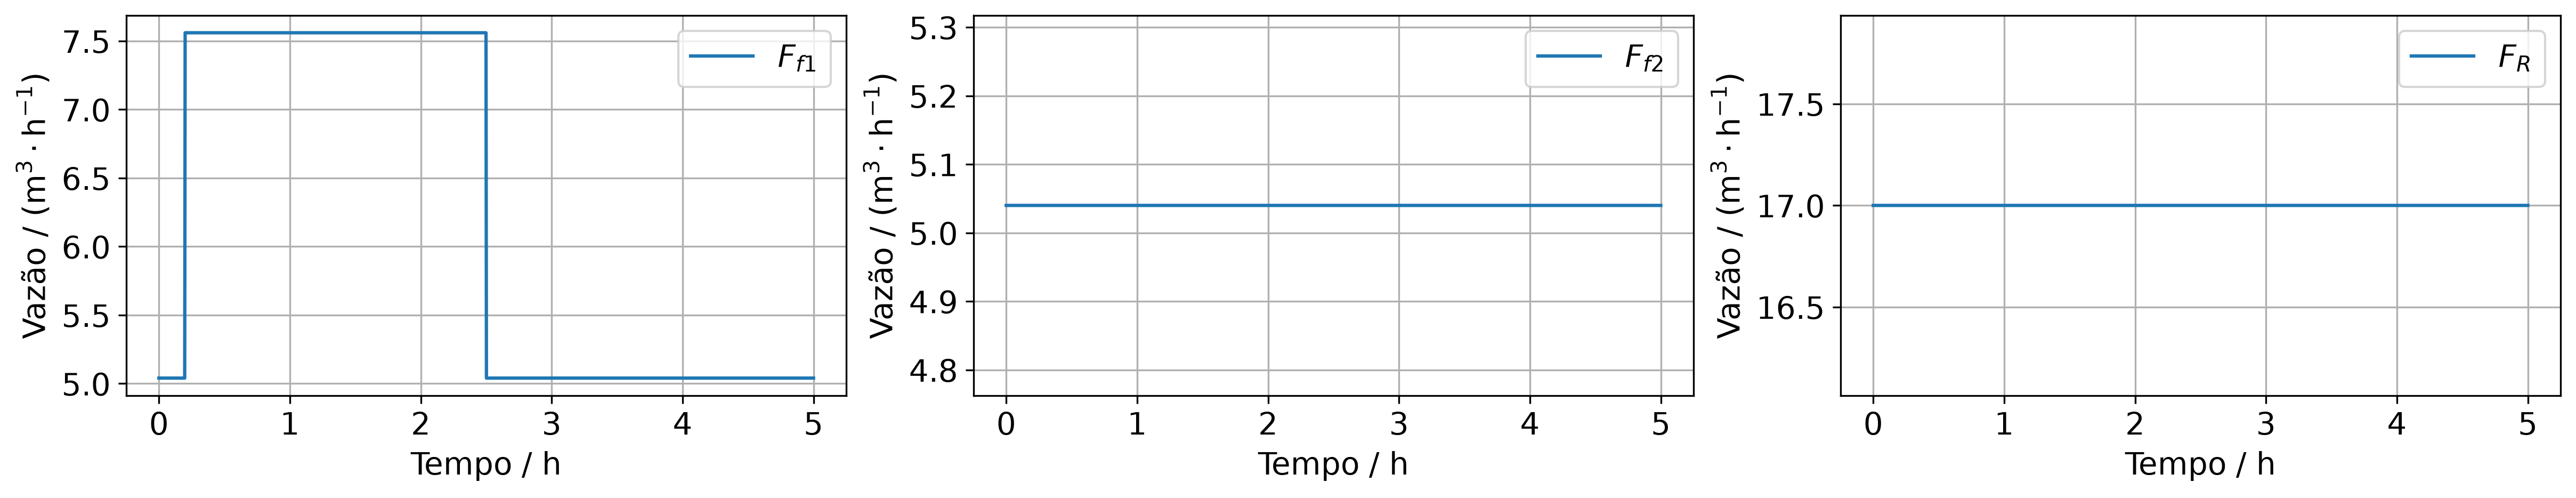

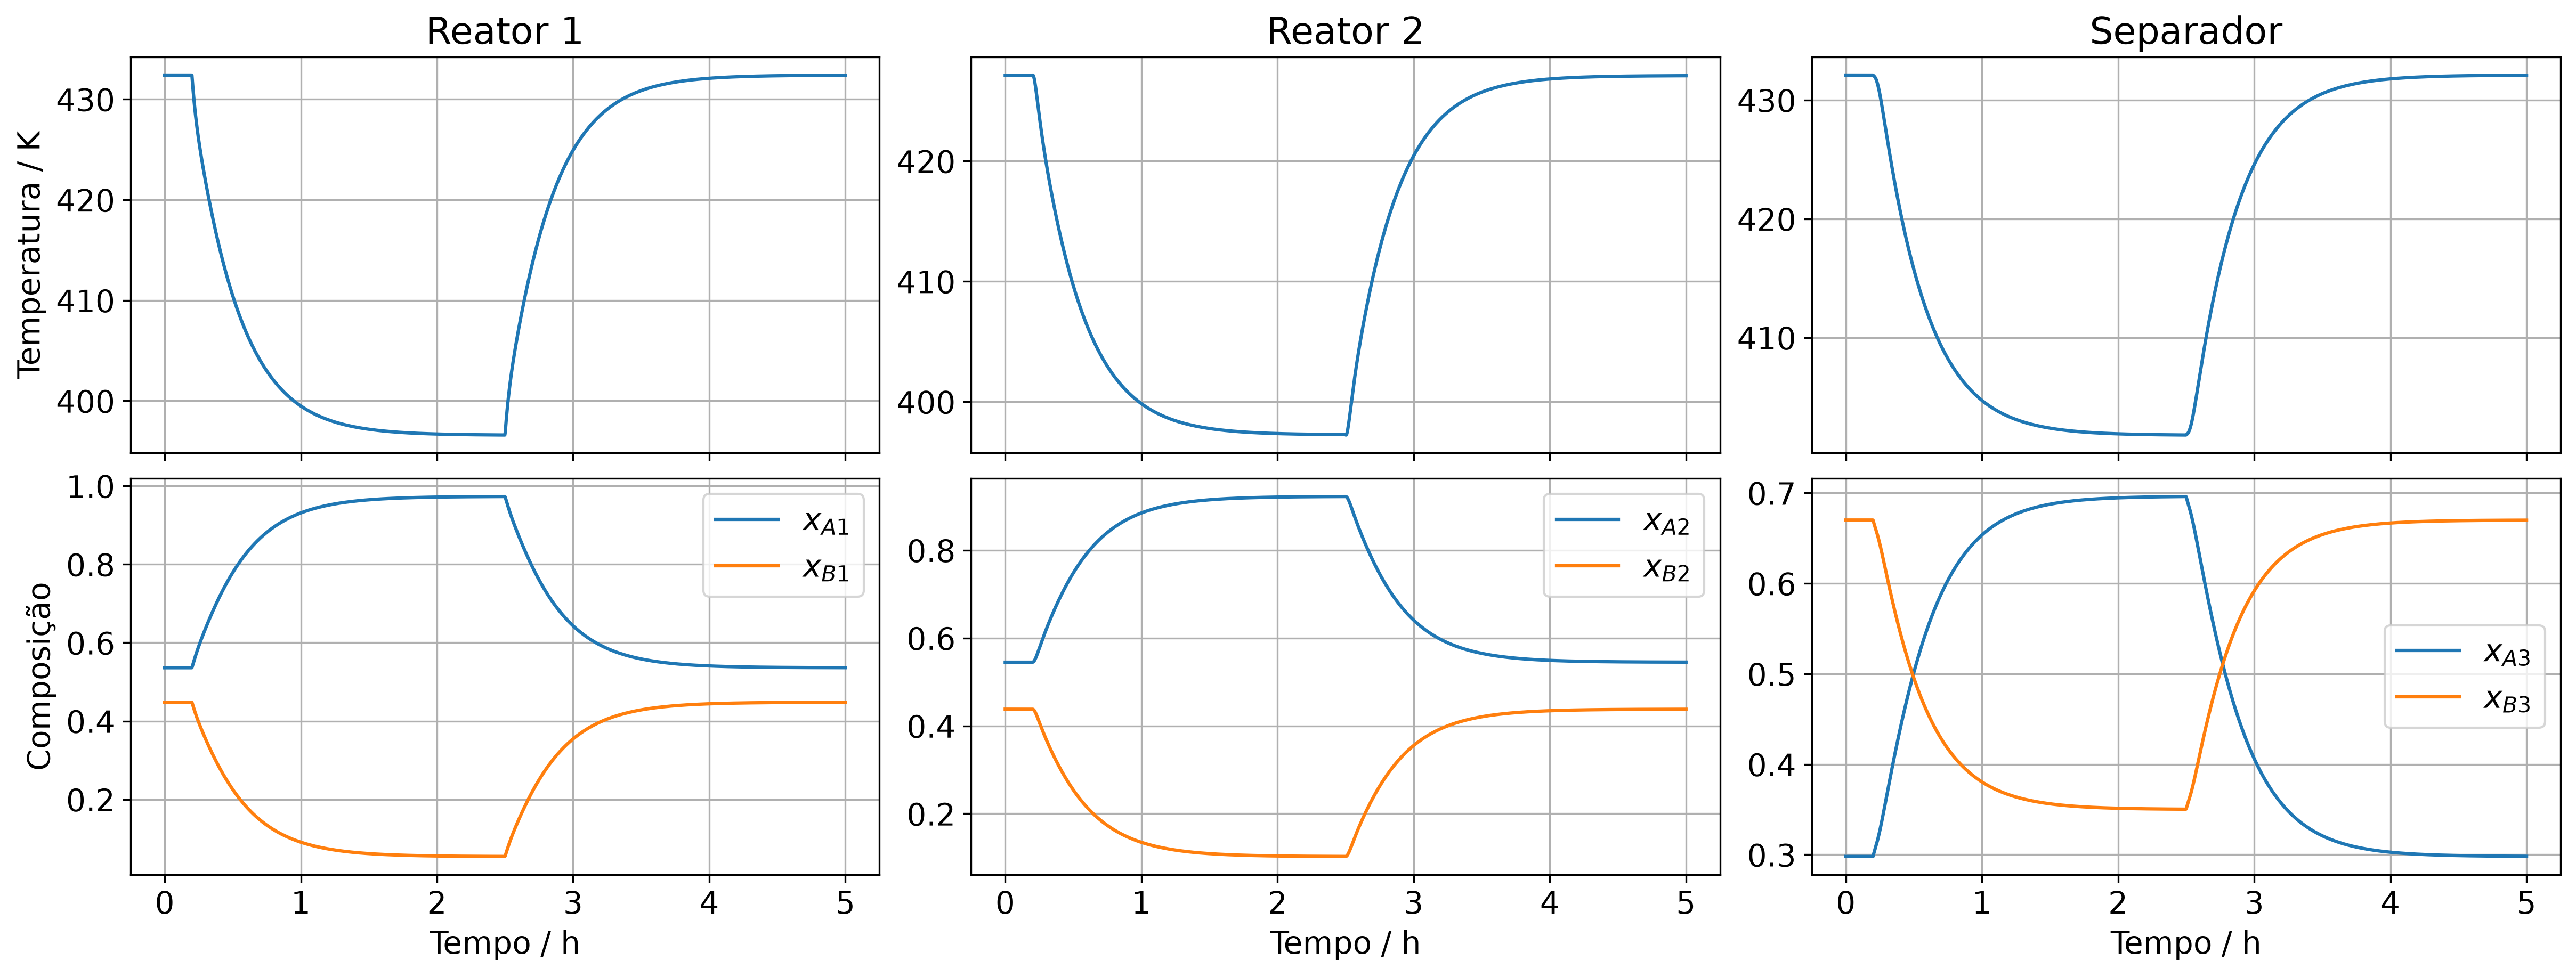

Pulso em Ff2: entradas e saídas do sistema linearizado


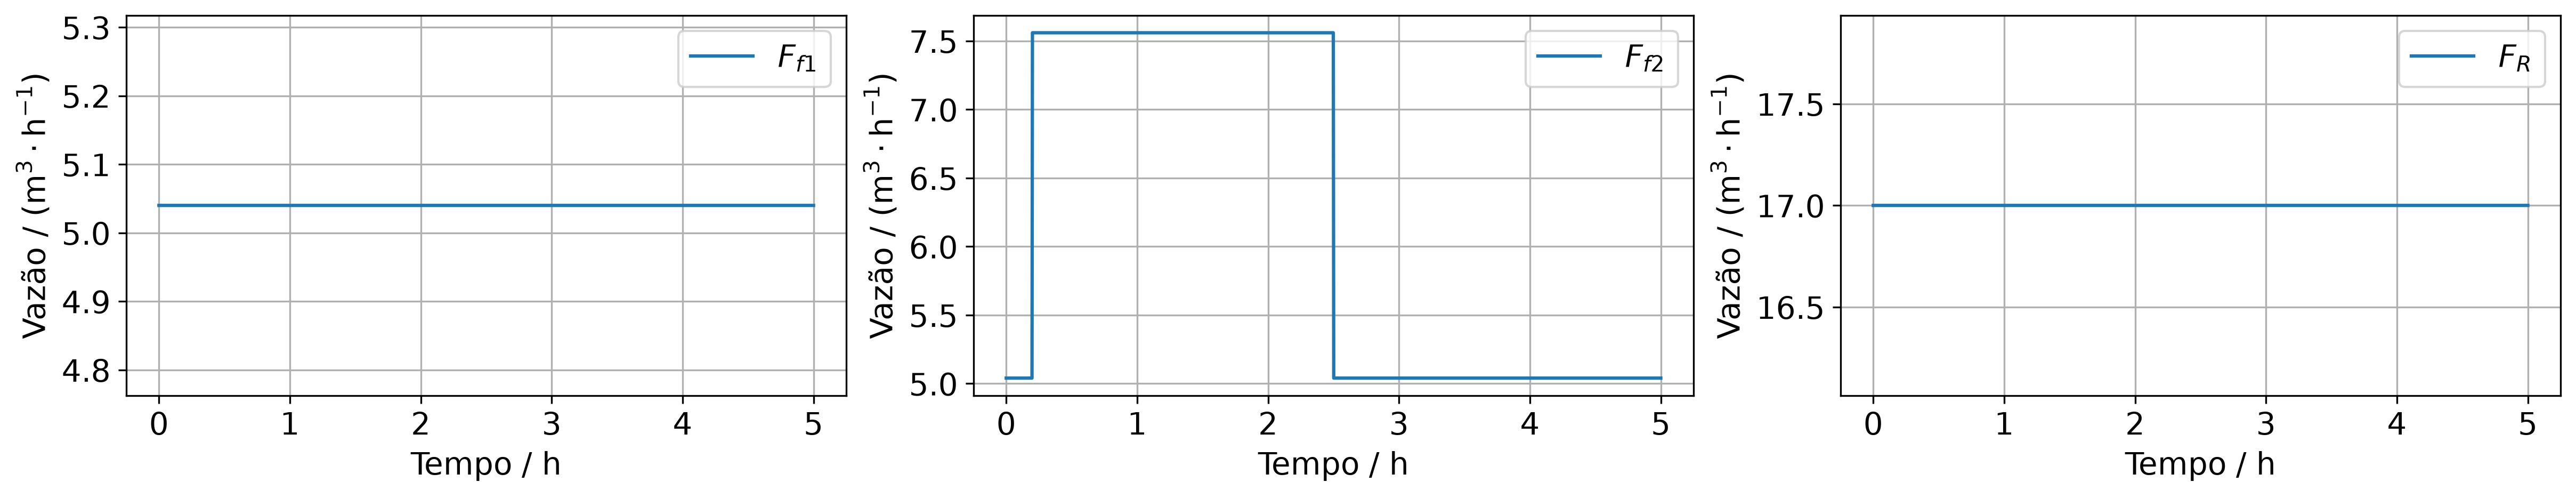

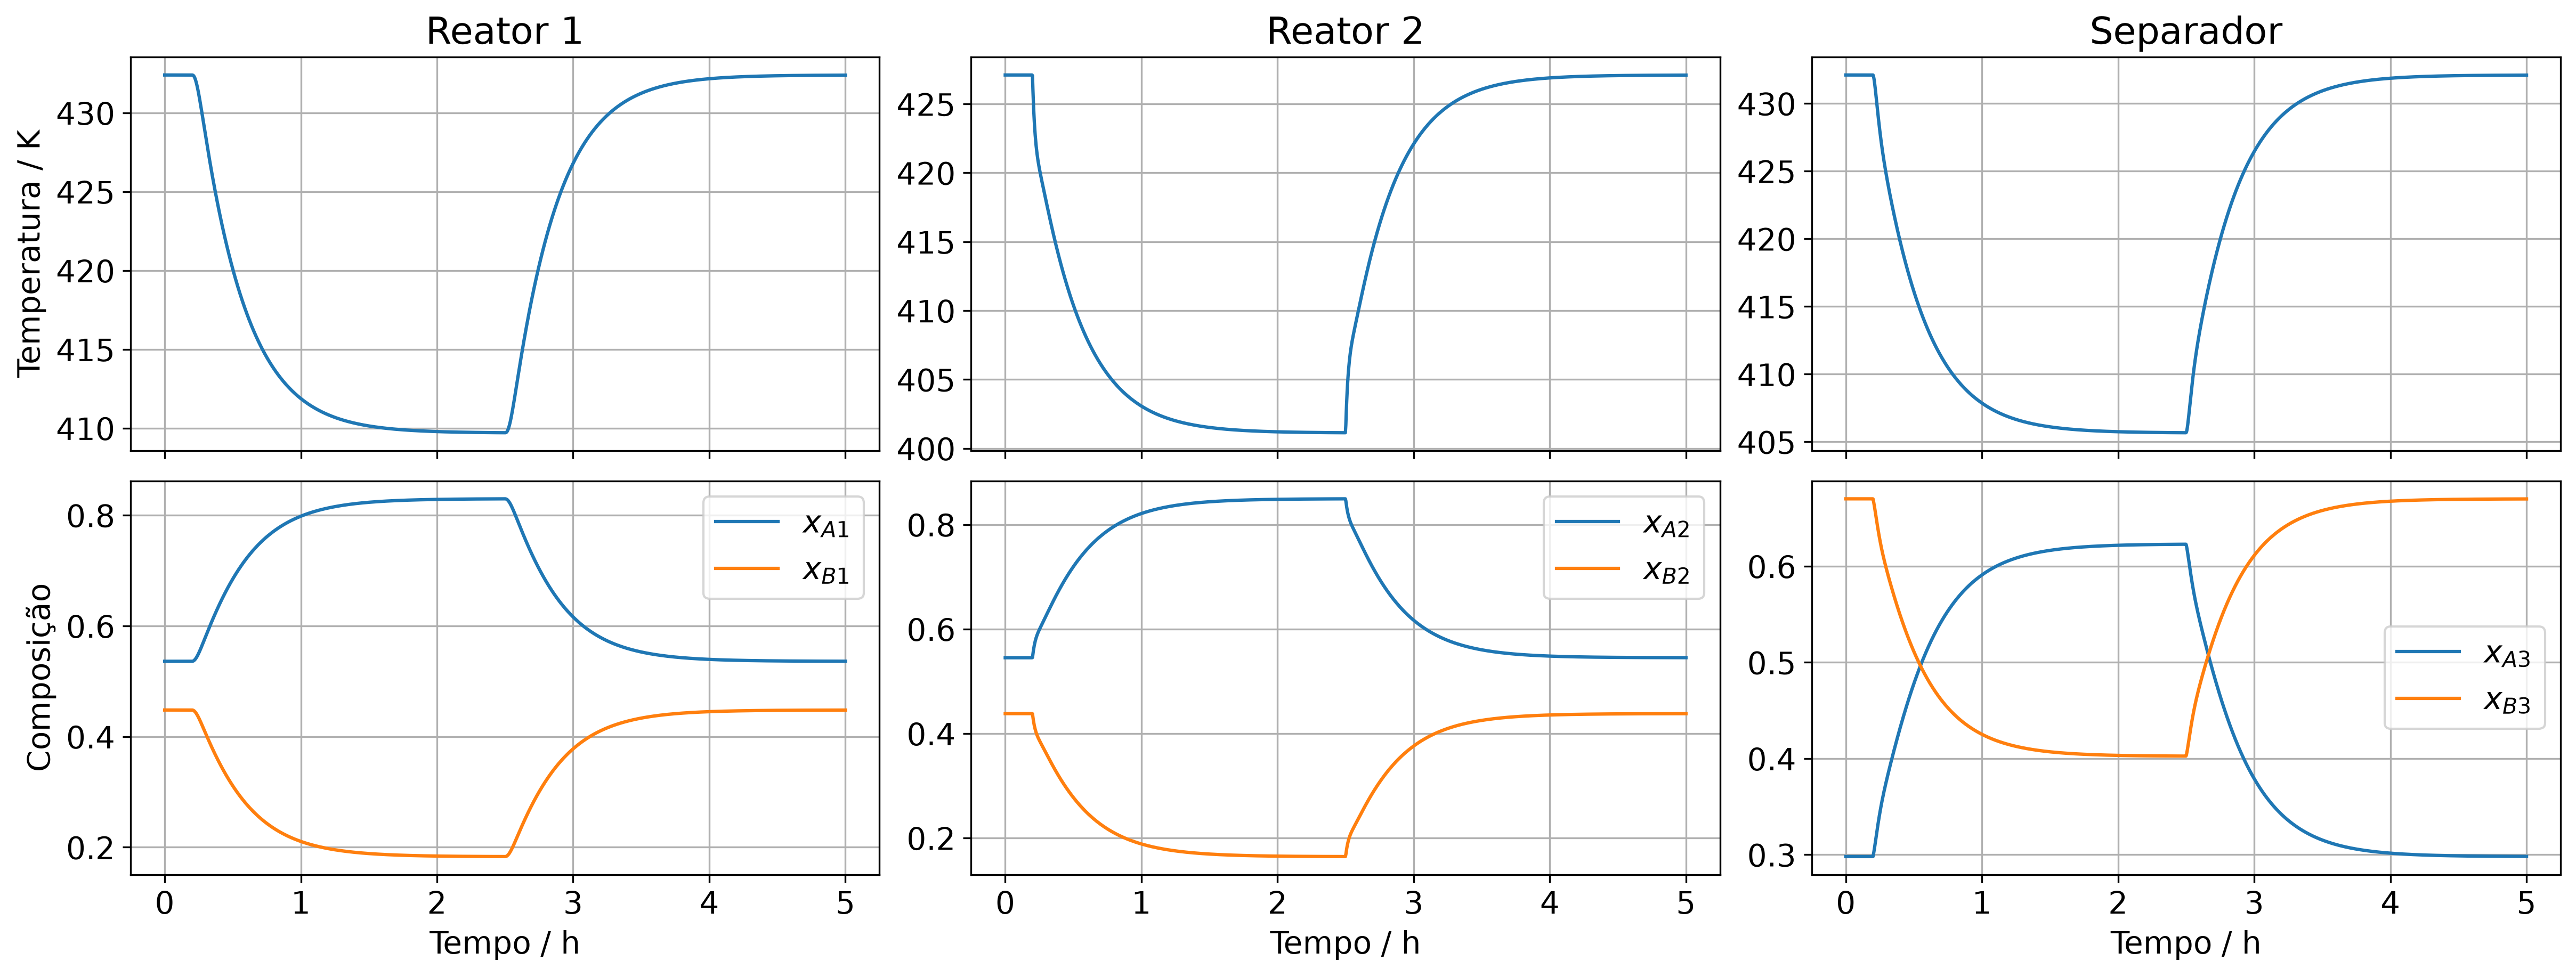

Pulso em FR: entradas e saídas do sistema linearizado


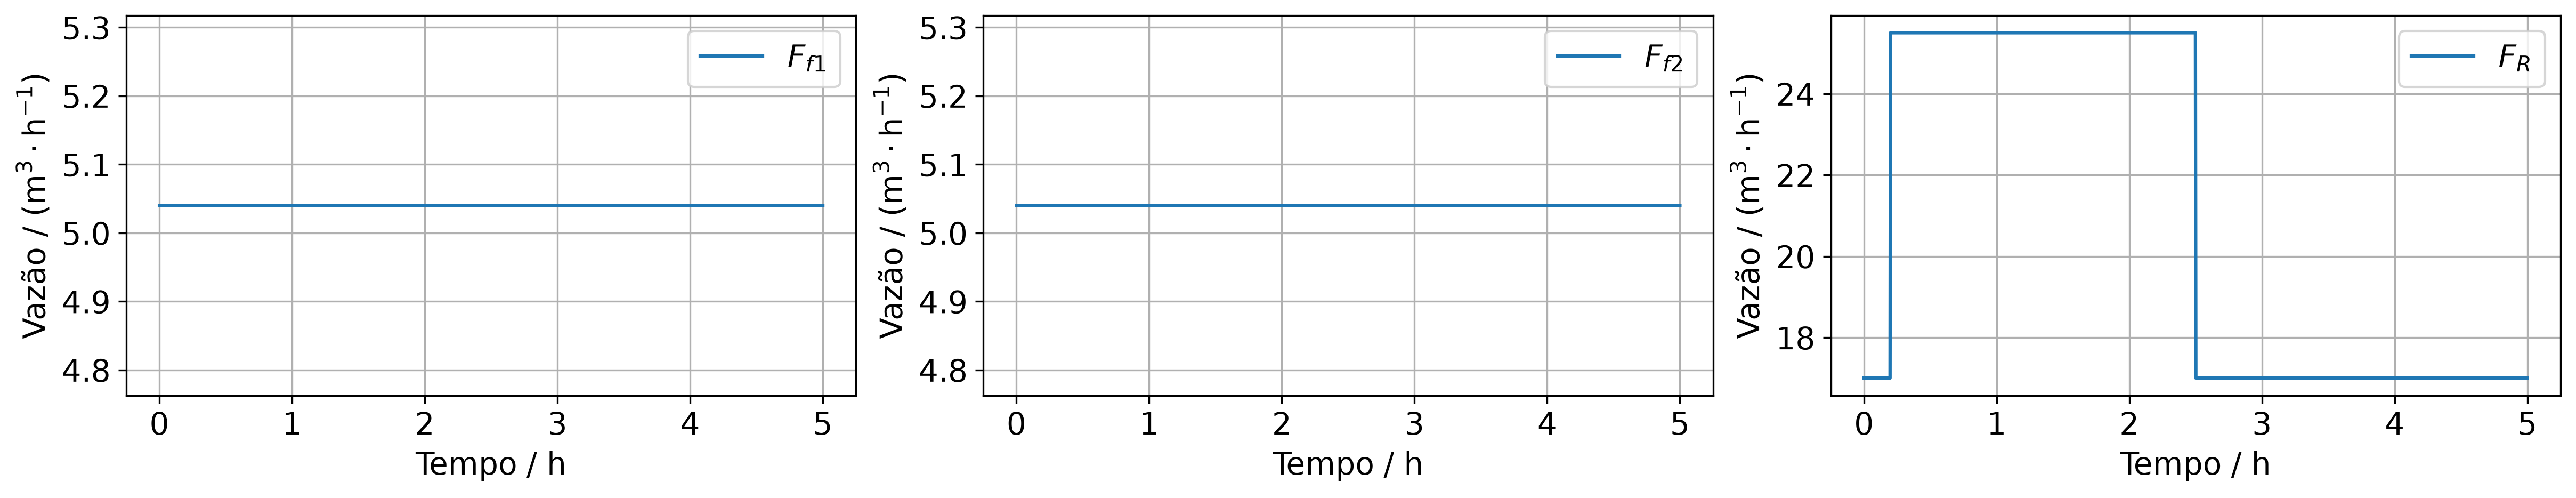

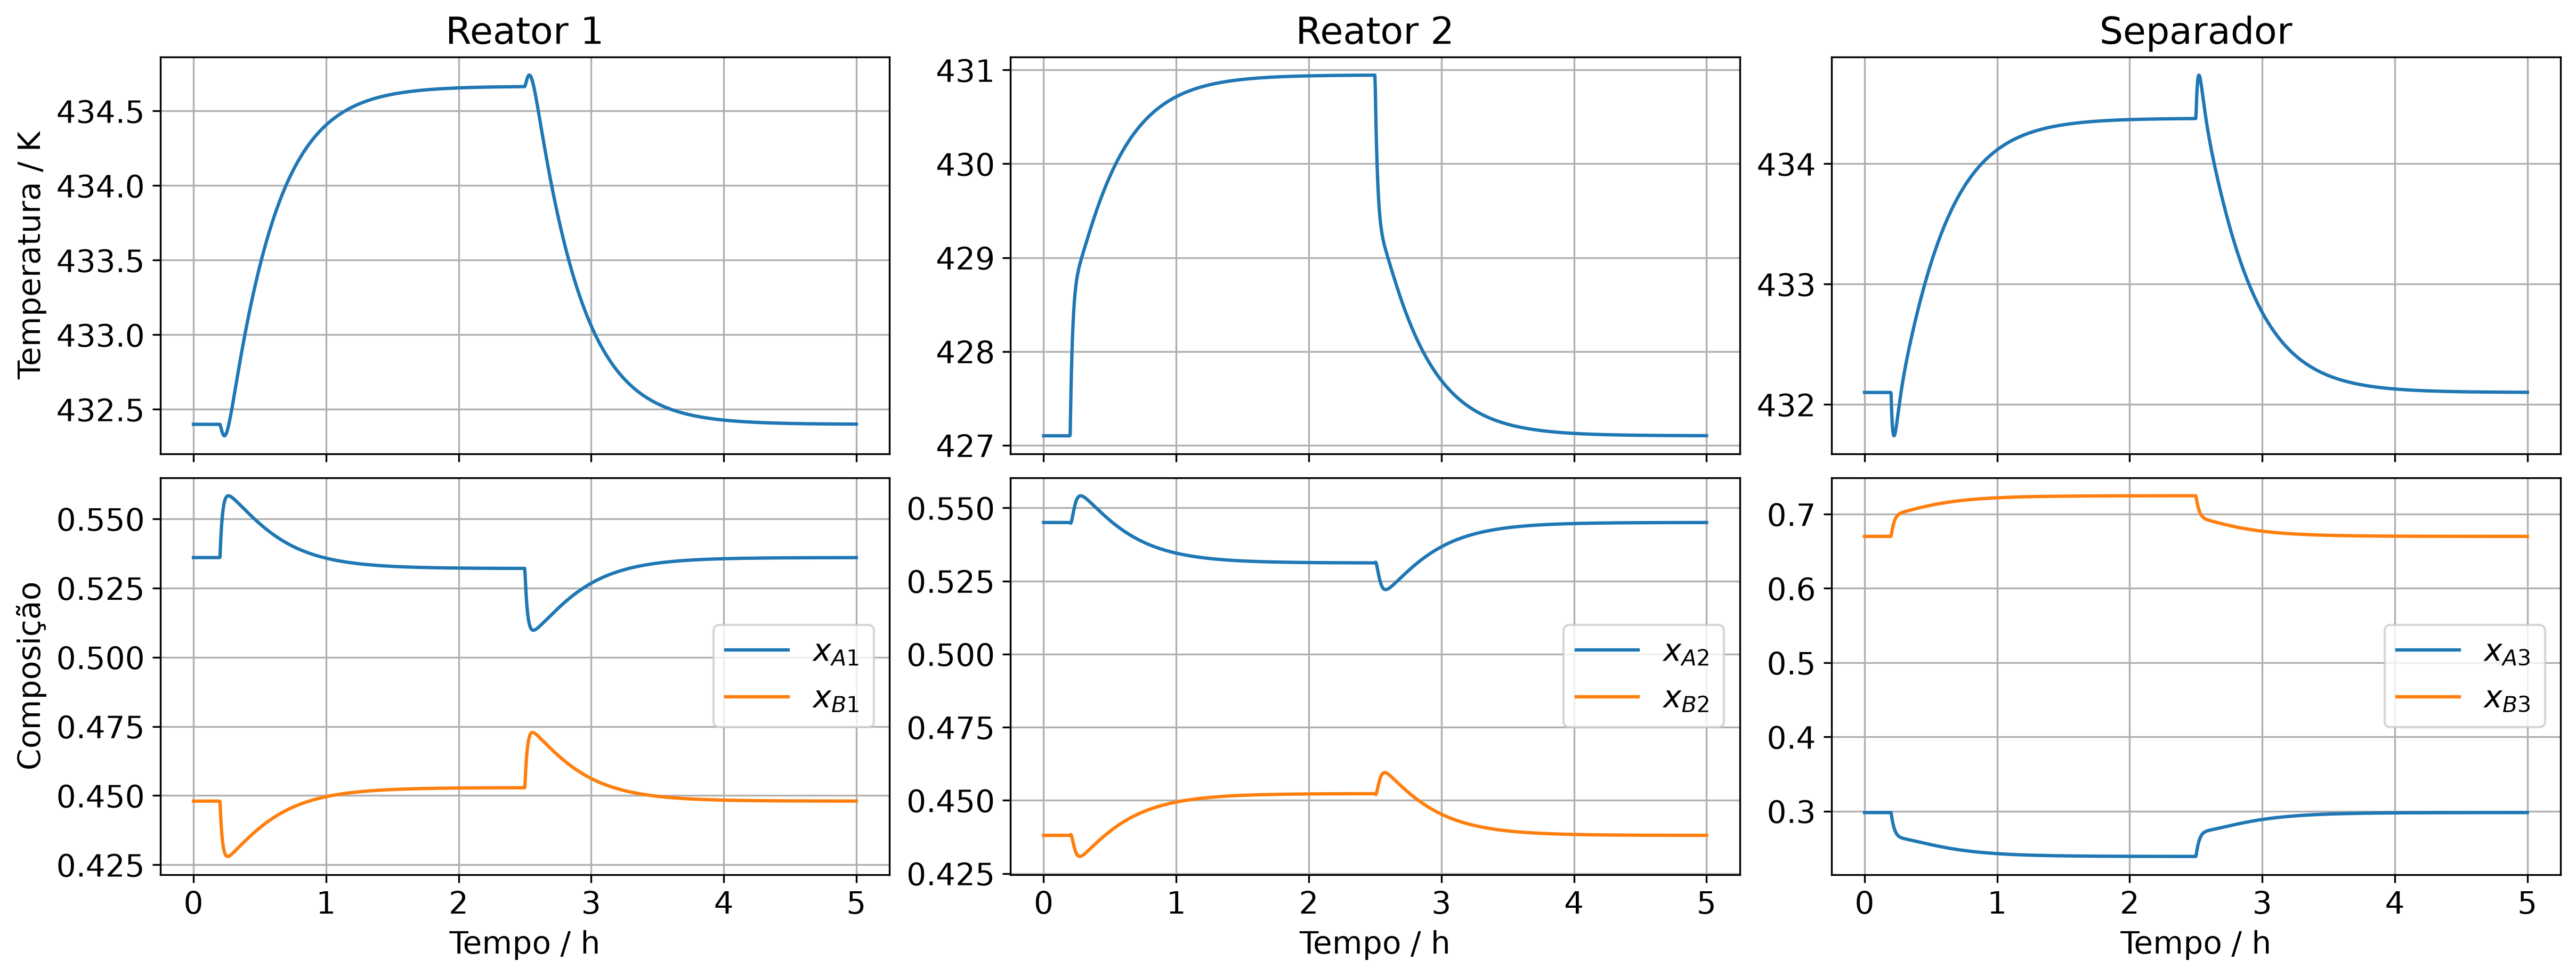

In [4]:
from scipy.integrate import solve_ivp

from lib.inputs import Ff1_func, Ff2_func, FR_func
from lib.parameters import y0
from lib.plots import plot_system_inputs, plot_system_outputs
from lib.utils import input_names

base_funcs = [Ff1_func, Ff2_func, FR_func]

t = np.linspace(0, 5, 1500)

for idx, name in enumerate(input_names):
    u = list(base_funcs)
    u[idx] = lambda t, f=base_funcs[idx]: f(t, disturb=True)  # type: ignore

    sol = solve_ivp(
        model,
        [t[0], t[-1]],
        np.zeros_like(y0),
        t_eval=t,
        args=(u,),
        rtol=1e-10,
        atol=1e-10,
    )

    u_eval = [ui(t) for ui in u]
    soly = sol.y + np.array(list(X0_vals.values()))[:, None]

    print(f"Pulso em {name}: entradas e saídas do sistema linearizado")
    plot_system_inputs(t, u_eval, f"linear/pulse-{name}-inputs")
    plot_system_outputs(t, soly, f"linear/pulse-{name}-outputs")


## Comparação entre os modelos linear e não linear

Os dois modelos são simulados com a mesma entrada, uma sequência de degraus em $F_{f1}$, e a fração molar $x_{B1}$ é plotada. Para a perturbação pequena, o modelo linear acompanha bem o não linear. À medida que a perturbação se afasta do ponto de operação, os modelos divergem e o linear chega a prever uma fração molar negativa, sem significado físico. Ao voltar ao valor nominal, as respostas voltam a coincidir. Assim, o modelo linearizado só é adequado para pequenas variações em torno do ponto de operação.


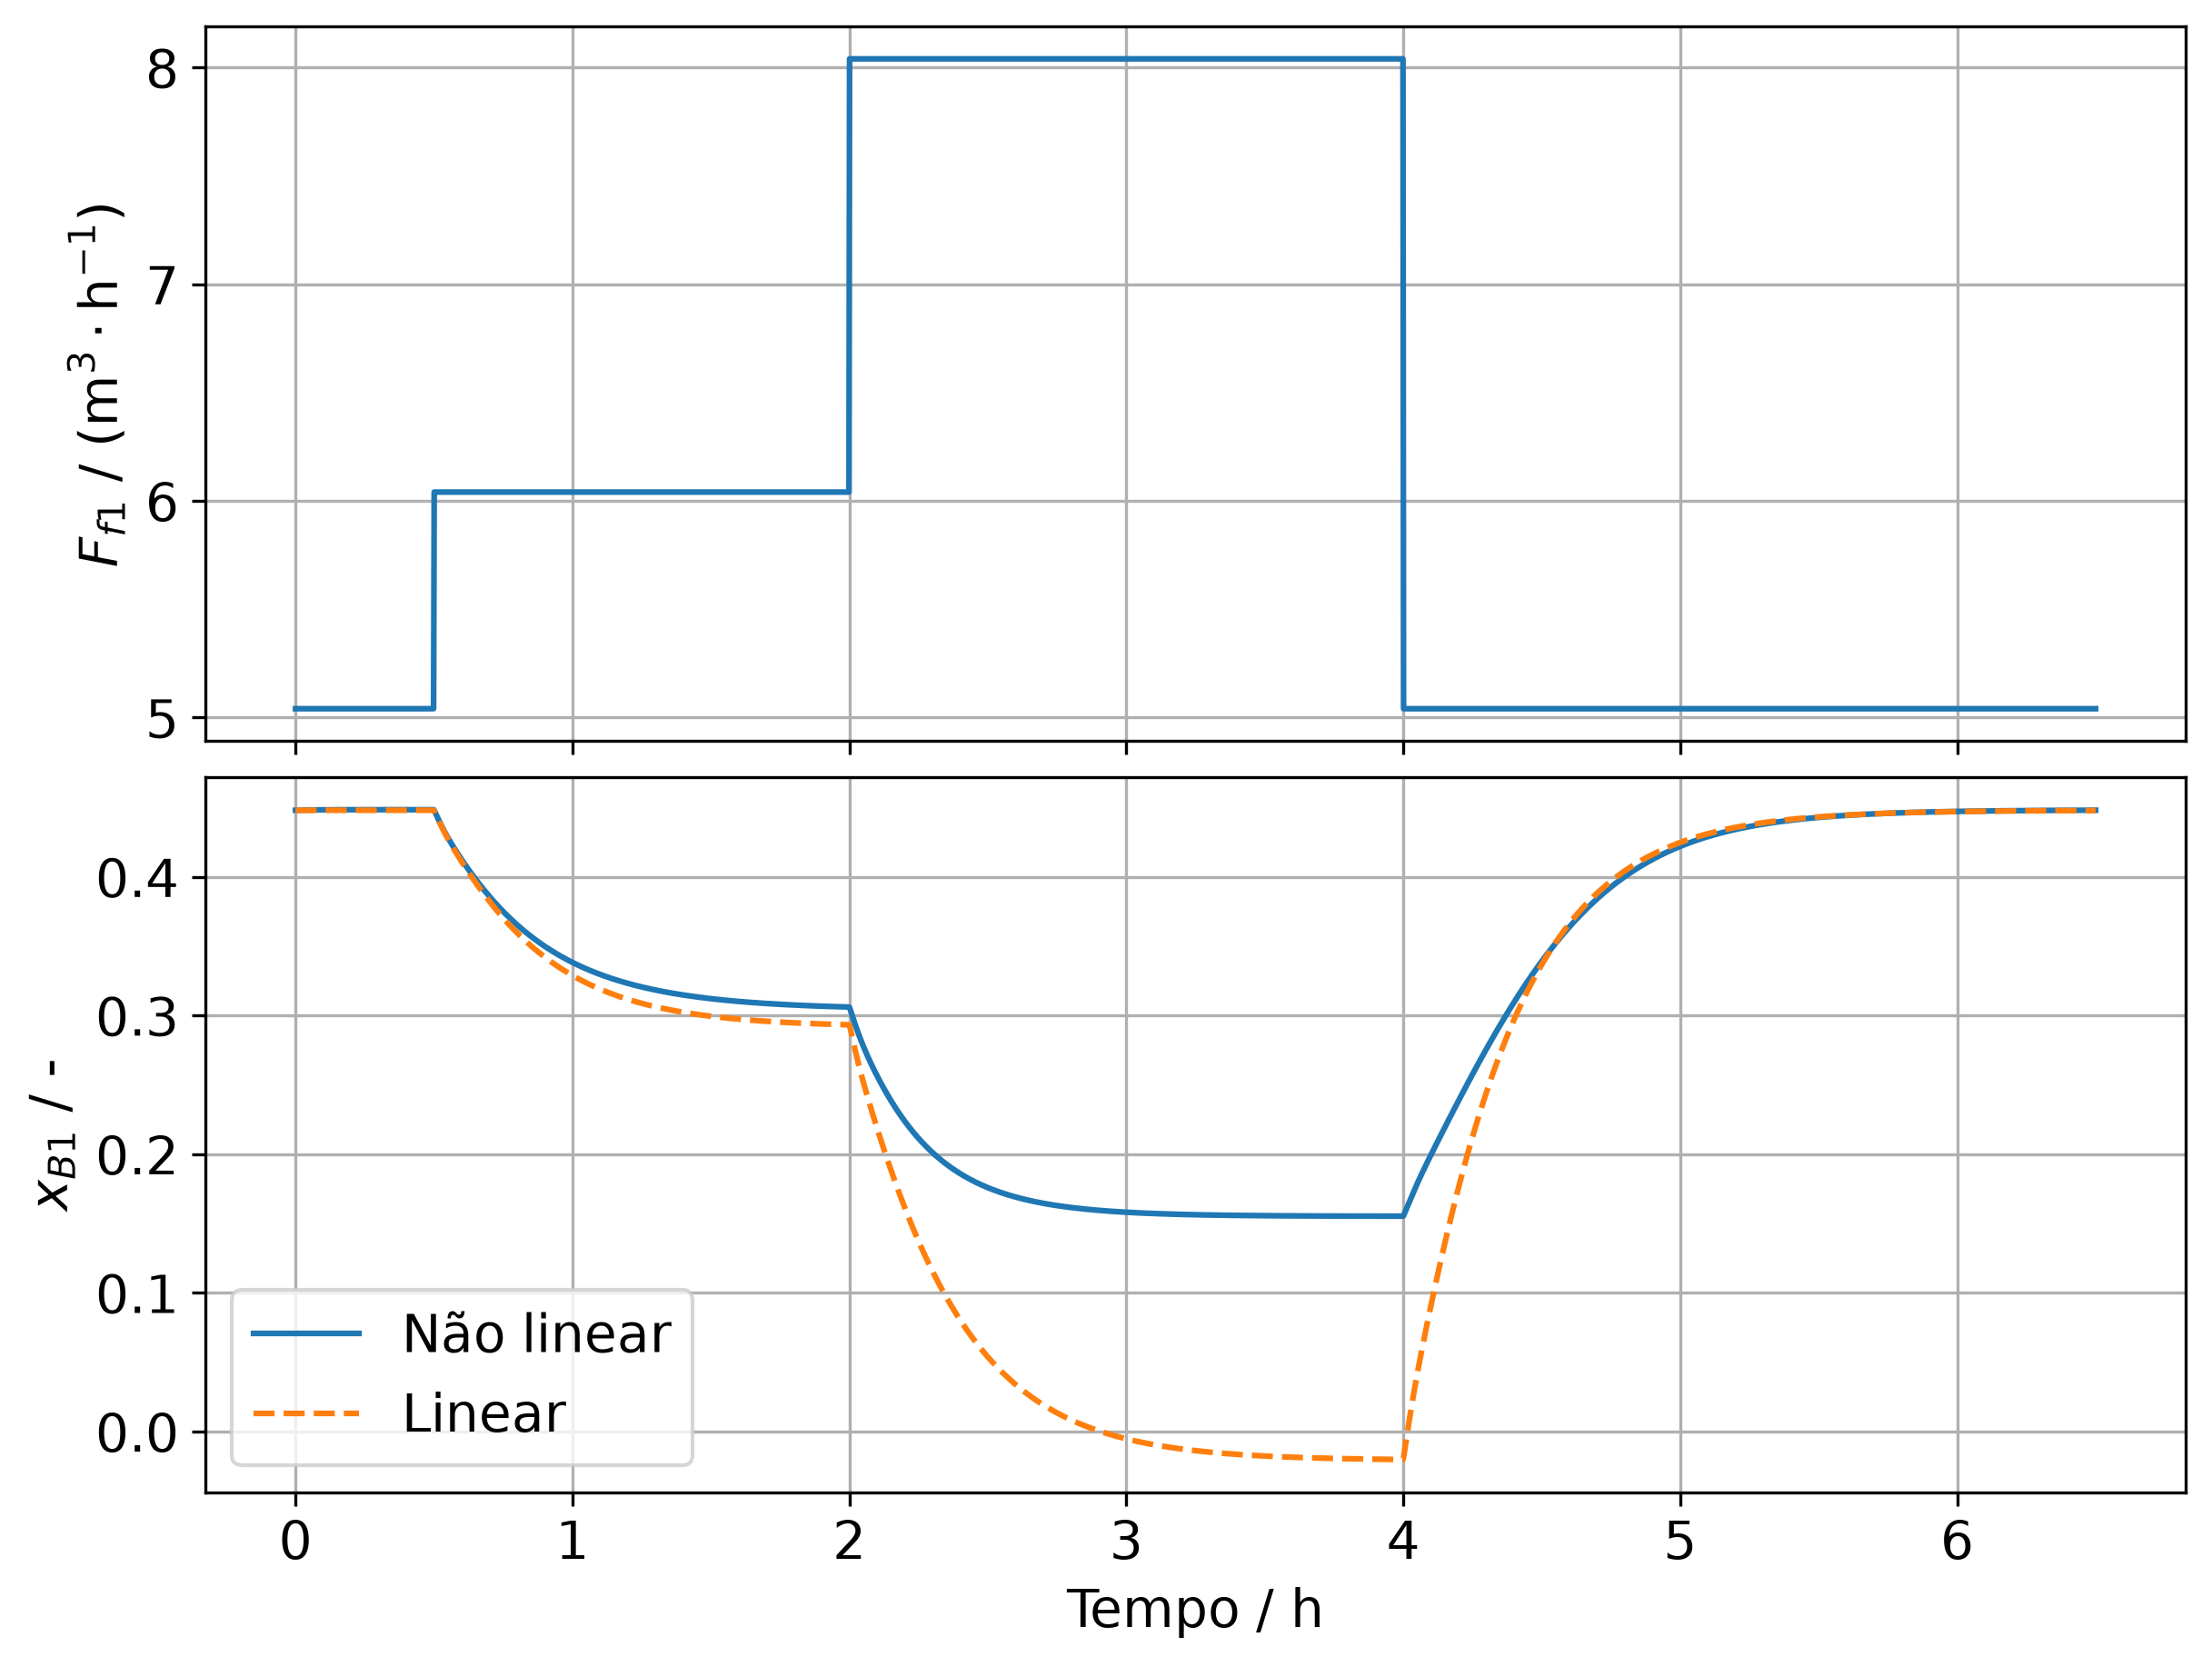

In [5]:
from lib.np_model import model as nonlinear_model
from lib.plots import plot_and_show, plt
from lib.utils import (
    input_labels,
    input_units,
    output_labels,
    output_names,
    output_units,
)


def Ff1_custom(t):
    if t < 0.5:
        return Ff1_0
    elif t < 2.0:
        return Ff1_0 + 1.0
    elif t < 4.0:
        return Ff1_0 + 3.0
    return Ff1_0


u = [Ff1_custom, Ff2_func, FR_func]

t = np.linspace(0, 6.5, 3000)

sol_nl = solve_ivp(
    nonlinear_model, [t[0], t[-1]], y0, t_eval=t, args=(u,), rtol=1e-10, atol=1e-10
)

sol_lin = solve_ivp(
    model, [t[0], t[-1]], np.zeros_like(y0), t_eval=t, args=(u,), rtol=1e-10, atol=1e-10
)

Y_lin = sol_lin.y + np.array(list(X0_vals.values()))[:, None]

# --- Plotting ---
input_id = 0
output_id = 4
G_name = f"{output_names[output_id]}_{input_names[input_id]}"
G_ylabel = f"{output_labels[output_id]} / {output_units[output_id]}"

Ff1_plot = np.array([Ff1_custom(tt) for tt in t])

fig, ax = plt.subplots(2, 1, sharex=True, figsize=(8, 6))

# Entrada: perturbação em Ff1
ax[0].plot(t, Ff1_plot)
ax[0].set_ylabel(f"{input_labels[input_id]} / {input_units[input_id]}")
ax[0].grid(True)

# Saída
ax[1].plot(sol_nl.t, sol_nl.y[output_id], label="Não linear")
ax[1].plot(sol_lin.t, Y_lin[output_id], "--", label="Linear")

ax[1].set_xlabel("Tempo / h")
ax[1].set_ylabel(G_ylabel)
ax[1].grid(True)
ax[1].legend()

plot_and_show(f"linear_vs_nonlinear/{G_name}")


## Exportação das matrizes

As matrizes $\mathbf{A}$, $\mathbf{B}$ e $\mathbf{C} = \mathbf{I}_9$ são salvas na pasta `outputs` no formato `.hkl` (hickle) para serem carregadas nos notebooks seguintes, sem precisar repetir a linearização.


In [6]:
from pathlib import Path

import hickle as hkl

OUT = Path("../outputs")

# converte de sympy para numpy (float)
A_np = np.array(A.tolist(), dtype=float)
B_np = np.array(B.tolist(), dtype=float)
C_np = np.eye(A_np.shape[0])

hkl.dump(A_np, OUT / "A.hkl")
hkl.dump(B_np, OUT / "B.hkl")
hkl.dump(C_np, OUT / "C.hkl")
